# code_174 · Adjustment depends on the intervention graph

**Book:** section 33.2. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_33_GUIDE.md), [execution evidence](../CHAPTER_33_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_174).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Treatments, estimands, observed versus simulator-only outcomes, fitting roles and independent assessment are declared below. Generated interventions do not establish causal identification from arbitrary operational logs or validate an individual counterfactual.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=6474;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 6474


<a id="graph-specific-adjustment"></a>
 ## Compare adjustment rules under three known data-generating graphs
 Run 80 independent studies of 2,000 buildings. In the confounder system, pre-treatment loadLaffects continuous maintenance intensityAand deteriorationY; its per-unit total treatment effect is−1. Compare unadjusted regression, load adjustment and an independently randomized intensity. In the mediator system, Achanges an intermediate responseMwhich then changesY: total effect−1 but controlled direct coefficient−0.4. Conditioning onMtargets a different quantity under this declared linear system. In the collider system, randomizedAand hiddenUboth cause post-treatment conditionC, whileUcausesYandAhas no effect. Conditioning onCcreates an association. Repetition SD describes study variability rather than a confidence interval for one study.


,procedure,estimand_truth,mean_estimate,study_SD,mean_bias
0,Confounded: raw,-1.0,-0.272287,0.026416,0.727713
1,Confounded: adjust L,-1.0,-1.002914,0.021106,-0.002914
2,Randomized: raw,-1.0,-0.998447,0.040864,0.001553
3,Mediator: total,-1.0,-1.002675,0.029750,-0.002675
4,Mediator: adjust M,-0.4,-0.399751,0.029055,0.000249
5,Collider: raw,0.0,0.001407,0.032360,0.001407
6,Collider: adjust C,0.0,-0.938898,0.029754,-0.938898


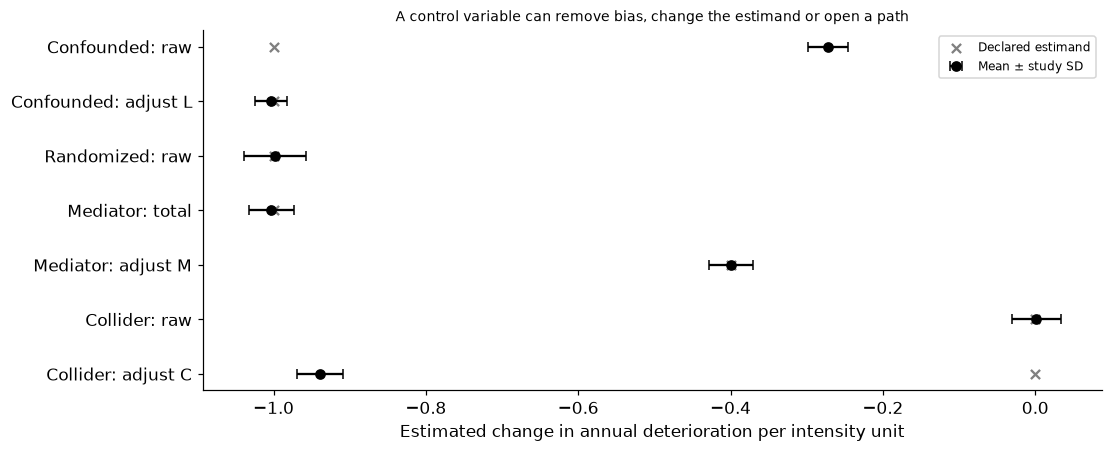

In [2]:
def slope(y,a,other=None):
    X=np.column_stack([np.ones(len(a)),a] if other is None else [np.ones(len(a)),a,other]);return float(np.linalg.lstsq(X,y,rcond=None)[0][1])
names=['Confounded: raw','Confounded: adjust L','Randomized: raw','Mediator: total','Mediator: adjust M','Collider: raw','Collider: adjust C'];truth=np.array([-1.,-1.,-1.,-1.,-.4,0.,0.]);studies=[]
for repeat in range(80):
    gr=np.random.default_rng(SEED+repeat);L=gr.normal(size=2000);A=.8*L+gr.normal(size=2000);Y=-A+1.5*L+gr.normal(size=2000);Ar=gr.normal(size=2000);Yr=-Ar+1.5*L+gr.normal(size=2000);Am=gr.normal(size=2000);M=.8*Am+gr.normal(size=2000);Ym=-.4*Am-.75*M+gr.normal(size=2000);Ac=gr.normal(size=2000);U=gr.normal(size=2000);C=Ac+U+.25*gr.normal(size=2000);Yc=U+gr.normal(size=2000);studies.append([slope(Y,A),slope(Y,A,L),slope(Yr,Ar),slope(Ym,Am),slope(Ym,Am,M),slope(Yc,Ac),slope(Yc,Ac,C)])
studies=np.array(studies);rows=[{'procedure':name,'estimand_truth':float(truth[j]),'mean_estimate':float(studies[:,j].mean()),'study_SD':float(studies[:,j].std(ddof=1)),'mean_bias':float(studies[:,j].mean()-truth[j])} for j,name in enumerate(names)];assert studies.shape==(80,7) and np.isfinite(studies).all();np.testing.assert_allclose(-.4+(-.75)*.8,-1.)
RESULTS.update(studies=80,buildings_per_study=2000,continuous_treatment_unit='one unit maintenance intensity',adjustment_results=rows,mediator_total_effect=-1.,mediator_controlled_direct_effect=-.4,collider_true_effect=0.);display(pd.DataFrame(rows));fig,ax=plt.subplots(figsize=(10,4));yy=np.arange(7);ax.errorbar(studies.mean(0),yy,xerr=studies.std(0,ddof=1),fmt='o',color='black',capsize=3,label='Mean ± study SD');ax.scatter(truth,yy,marker='x',color='.5',label='Declared estimand');ax.set(yticks=yy,yticklabels=names,xlabel='Estimated change in annual deterioration per intensity unit',title='A control variable can remove bias, change the estimand or open a path');ax.invert_yaxis();ax.legend(fontsize=8);plt.show()


<a id="adjustment-sets-and-overlap"></a>
 ## Observe when an adjustment set cannot supply a missing comparison
 The graphs define L=pre-treatment load, A=maintenance intensity, M=post-maintenance response, C=post-treatment selection/condition, U=hidden severity and Y=annual deterioration. For a total effect, adjustLunder the first graph, avoid blockingMunder the second, and avoid conditioning onCunder the third. The linear mediator's direct coefficient relies on its own no-confounding/error assumptions; merely adding a measured mediator does not identify a direct effect in arbitrary data. Separately assign binary treatment deterministically from the sign of load: every load region then lacks one treatment arm. No outcome-regression extrapolation turns those missing comparisons into observed overlap.


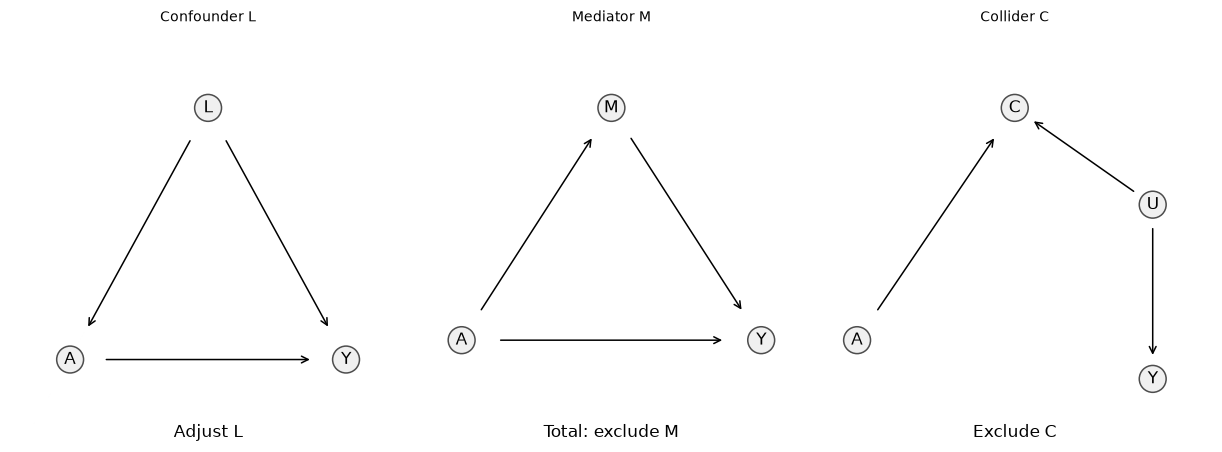

In [3]:
bins=np.linspace(-2,2,9);load=np.linspace(-1.99,1.99,2000);assigned=(load>0).astype(int);coverage=np.array([[np.sum((load>=lo)&(load<hi)&(assigned==a)) for a in [0,1]] for lo,hi in zip(bins[:-1],bins[1:])]);assert np.all((coverage==0).sum(1)==1) and np.all(coverage.sum(1)>0)
RESULTS.update(deterministic_assignment_bin_counts=coverage.tolist(),positivity_failure_every_load_bin=True,adjustment_sets={'confounder_total':['L'],'mediator_total':[],'collider_total':[]})
fig,axes=plt.subplots(1,3,figsize=(11,4));specs=[('Confounder L',{'A':(.15,.15),'Y':(.85,.15),'L':(.5,.8)},[('L','A'),('L','Y'),('A','Y')],'Adjust L'),('Mediator M',{'A':(.12,.2),'M':(.5,.8),'Y':(.88,.2)},[('A','M'),('M','Y'),('A','Y')],'Total: exclude M'),('Collider C',{'A':(.1,.2),'C':(.5,.8),'U':(.85,.55),'Y':(.85,.1)},[('A','C'),('U','C'),('U','Y')],'Exclude C')]
for ax,(title,pos,edges,note) in zip(axes,specs):
    ax.axis('off');ax.set_title(title)
    for node,(x,y) in pos.items():ax.text(x,y,node,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'circle','facecolor':'.94','edgecolor':'.3'})
    for start,end in edges:
        a=np.array(pos[start]);b=np.array(pos[end]);d=b-a;ax.annotate('',xy=b-.12*d,xytext=a+.12*d,xycoords='axes fraction',arrowprops={'arrowstyle':'->'})
    ax.text(.5,-.05,note,ha='center',transform=ax.transAxes)
plt.show()


In [4]:
summary={'example_id':'code_174','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual repeated confounder mediator and collider structural simulations', 'randomized treatment control and declared total versus direct effects', 'observed regression adjustment can remove or introduce bias', 'structural positivity failure diagnosed by load regions', 'three defined DAGs with proposed adjustment sets'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual repeated confounder mediator and collider structural simulations", "randomized treatment control and declared total versus direct effects", "observed regression adjustment can remove or introduce bias", "structural positivity failure diagnosed by load regions", "three defined DAGs with proposed adjustment sets"], "elapsed_seconds": 0.475, "example_id": "code_174", "hardware": "Darwin arm64 CPU", "results": {"adjustment_results": [{"estimand_truth": -1.0, "mean_bias": 0.7277134484010896, "mean_estimate": -0.27228655159891035, "procedure": "Confounded: raw", "study_SD": 0.026416356361621342}, {"estimand_truth": -1.0, "mean_bias": -0.0029135487310258945, "mean_estimate": -1.002913548731026, "procedure": "Confounded: adjust L", "study_SD": 0.021106179926117637}, {"estimand_truth": -1.0, "mean_bias": 0.00155280512285072, "mean_estimate": -0.9984471948771493, "procedure": "Randomized: raw", "study_SD": 0.04086405417308315}, {"estimand